
# IDC409: 02 EDA (Random Forrest Model)
Upload stocks_data_clean.csv and daily_sentiment_scores.csv to Colab first: click the folder icon on the left, then the upload icon. Run the cells top to bottom.

Combining both stocks and news headlines into one final dataset

In [7]:
!pip install -q yfinance openpyxl

import pandas as pd, numpy as np, yfinance as yf

P = "/content/"   # upload daily_sentiment_scores.csv and stocks_data_clean.csv here

# ---------- 1. stock file + NVDA volume (the CSV has closing prices only) ----------
stocks = pd.read_csv(P + "stocks_data_clean.csv", parse_dates=["date"]).sort_values("date").reset_index(drop=True)
stocks = stocks[["date", "stock", "gold", "oil", "usdinr", "stock_ret", "gold_ret", "oil_ret", "usdinr_ret"]]

vol = yf.download("NVDA", start=stocks["date"].min(), end=stocks["date"].max() + pd.Timedelta(days=2),
                  auto_adjust=True, progress=False)
if isinstance(vol.columns, pd.MultiIndex):
    vol.columns = vol.columns.get_level_values(0)
vol = vol[["Volume"]].rename(columns={"Volume": "volume"}).reset_index().rename(columns={"Date": "date"})
vol["date"] = pd.to_datetime(vol["date"]).dt.tz_localize(None)
stocks = stocks.merge(vol, on="date", how="left")
print("missing volume rows:", stocks["volume"].isna().sum())     # should be 0 or tiny
stocks["volume"] = stocks["volume"].ffill()

# ---------- 2. load the precomputed daily sentiment and map it to trading days ----------
ds = pd.read_csv(P + "daily_sentiment_scores.csv", parse_dates=["date"]).sort_values("date")

# the file is by calendar day, so weekend/holiday news rolls into the next trading day
ds = pd.merge_asof(ds, stocks[["date"]].rename(columns={"date": "trade_date"}),
                   left_on="date", right_on="trade_date", direction="forward").dropna(subset=["trade_date"])

daily = (ds.groupby("trade_date")
           .agg(sentiment_sum=("sentiment_sum", "sum"), n_headlines=("n_headlines", "sum"))
           .reset_index().rename(columns={"trade_date": "date"}))
daily["sentiment"] = daily["sentiment_sum"] / daily["n_headlines"]   # exact mean over all pooled headlines
daily = daily[["date", "sentiment", "n_headlines"]]

# ---------- 3. merge and build features ----------
df = stocks.merge(daily, on="date", how="left")
first_news = daily["date"].min()
print("first trading day with news:", first_news.date(), "| last:", daily["date"].max().date())

df["news_covered"] = df["n_headlines"].notna().astype(int)
df["n_headlines"] = df["n_headlines"].fillna(0).astype(int)
after = df["date"] >= first_news
df.loc[after, "sentiment"] = df.loc[after, "sentiment"].fillna(0)   # no news inside the window = neutral 0
df.loc[~after, "sentiment"] = np.nan                                 # before news exists = unknown

p = df["stock"]
# --- sentiment features ---
df["sent_3d"] = df["sentiment"].rolling(3).mean()
df["sent_5d"] = df["sentiment"].rolling(5).mean()
for k in (1, 3, 5):
    df[f"lag_sentiment_{k}d"] = df["sentiment"].shift(k)

# --- price features (today and earlier only) ---
df["daily_return"] = p.pct_change()
df["log_return"] = np.log(p / p.shift(1))
for w in (3, 5, 10):
    df[f"volatility_{w}d"] = df["daily_return"].rolling(w).std()
df["volume_change"] = df["volume"].pct_change()
df["volume_ma_5d"] = df["volume"].rolling(5).mean()
df["price_ma_5d"] = p.rolling(5).mean()
df["price_ma_10d"] = p.rolling(10).mean()
df["price_ma_ratio"] = df["price_ma_5d"] / df["price_ma_10d"]

# --- interactions ---
df["sentiment_x_return"] = df["sentiment"] * df["daily_return"]
df["sentiment_x_vol"] = df["sentiment"] * df["volatility_5d"]

# --- target: tomorrow (NOT a feature) ---
df["target_return"] = df["daily_return"].shift(-1)
df["target_up"] = (df["target_return"] > 0).astype(int)

features = ['sentiment', 'sent_3d', 'sent_5d', 'lag_sentiment_1d', 'lag_sentiment_3d', 'lag_sentiment_5d',
            'daily_return', 'log_return', 'volatility_3d', 'volatility_5d', 'volatility_10d',
            'volume_change', 'volume_ma_5d', 'price_ma_5d', 'price_ma_10d', 'price_ma_ratio',
            'sentiment_x_return', 'sentiment_x_vol']

# ---------- 4. keep only the window where both news and prices exist ----------
final = (df[df["date"] >= first_news]
         .dropna(subset=features + ["target_return"])
         .reset_index(drop=True))

keep = (["date", "stock", "gold", "oil", "usdinr", "stock_ret", "gold_ret", "oil_ret", "usdinr_ret",
         "volume", "n_headlines", "news_covered"] + features + ["target_return", "target_up"])
final = final[keep]
final.to_csv("final_dataset.csv", index=False)
print(final.shape, final["date"].min().date(), "->", final["date"].max().date())

from google.colab import files
files.download("final_dataset.csv")

missing volume rows: 53
first trading day with news: 2022-10-20 | last: 2026-10-20
(1042, 32) 2022-10-27 -> 2026-10-29


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Load Features and split

In [8]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score, classification_report)
from sklearn.tree import plot_tree

data = pd.read_csv("final_dataset.csv", parse_dates=["date"], index_col="date").dropna()
# target_return (tomorrow's return) is already in the file, so there is no need to shift again

price_feats = ["daily_return", "log_return", "volatility_3d", "volatility_5d", "volatility_10d",
               "volume_change", "price_ma_ratio"]            # scale-free price features
level_feats = ["volume_ma_5d", "price_ma_5d", "price_ma_10d"]  # raw levels (can hurt, see note)
sent_feats  = ["sentiment", "sent_3d", "sent_5d", "lag_sentiment_1d", "lag_sentiment_3d",
               "lag_sentiment_5d", "sentiment_x_return", "sentiment_x_vol"]

features = price_feats + level_feats + sent_feats   # all 18 features, raw levels included

split = int(len(data) * 0.8)                       # oldest 80% train, newest 20% test
train, test = data.iloc[:split], data.iloc[split:]
X_train, y_train = train[features], train["target_return"]
X_test,  y_test  = test[features],  test["target_return"]
print("Train:", len(train), "| Test:", len(test))

Train: 833 | Test: 209


Train model

In [9]:
rf = RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=10,
                           random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
pred_s = pd.Series(pred, index=test.index)

print("Random Forest (price + news)")
print(f"  MAE : {mean_absolute_error(y_test, pred):.4f}")
print(f"  RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.4f}")
print(f"  R²  : {r2_score(y_test, pred):.4f}")

base = test["daily_return"]                      # baseline: tomorrow = today
print("Baseline (tomorrow = today)")
print(f"  MAE : {mean_absolute_error(y_test, base):.4f}")
print(f"  RMSE: {np.sqrt(mean_squared_error(y_test, base)):.4f}")

Random Forest (price + news)
  MAE : 0.0183
  RMSE: 0.0236
  R²  : -0.0199
Baseline (tomorrow = today)
  MAE : 0.0253
  RMSE: 0.0338


Confusion matrix

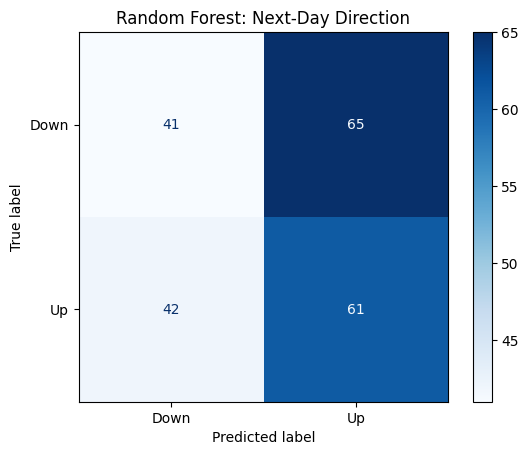

TN=41 FP=65 FN=42 TP=61
              precision    recall  f1-score   support

        Down       0.49      0.39      0.43       106
          Up       0.48      0.59      0.53       103

    accuracy                           0.49       209
   macro avg       0.49      0.49      0.48       209
weighted avg       0.49      0.49      0.48       209

Model     accuracy: 0.488 | F1: 0.533
Baseline  accuracy: 0.545 | F1: 0.541
Always-Up accuracy: 0.493


In [10]:
y_true_dir = (y_test > 0).astype(int)        # 1 = Up, 0 = Down/flat
y_pred_dir = (pred_s > 0).astype(int)

cm = confusion_matrix(y_true_dir, y_pred_dir, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Down", "Up"]).plot(cmap="Blues")
plt.title("Random Forest: Next-Day Direction")
plt.savefig("confusion_matrix.png", dpi=150); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print(classification_report(y_true_dir, y_pred_dir, target_names=["Down", "Up"], zero_division=0))

base_dir = (test["daily_return"] > 0).astype(int)
print("Model     accuracy:", round(accuracy_score(y_true_dir, y_pred_dir), 3),
      "| F1:", round(f1_score(y_true_dir, y_pred_dir), 3))
print("Baseline  accuracy:", round(accuracy_score(y_true_dir, base_dir), 3),
      "| F1:", round(f1_score(y_true_dir, base_dir), 3))
print("Always-Up accuracy:", round(y_true_dir.mean(), 3))

Feature importance, Actual vs Predicted over time, Scatter of actual vs predicted

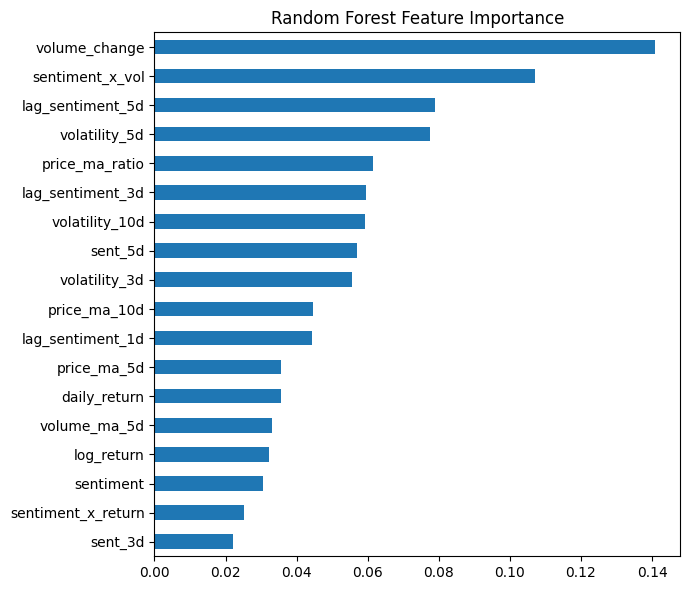

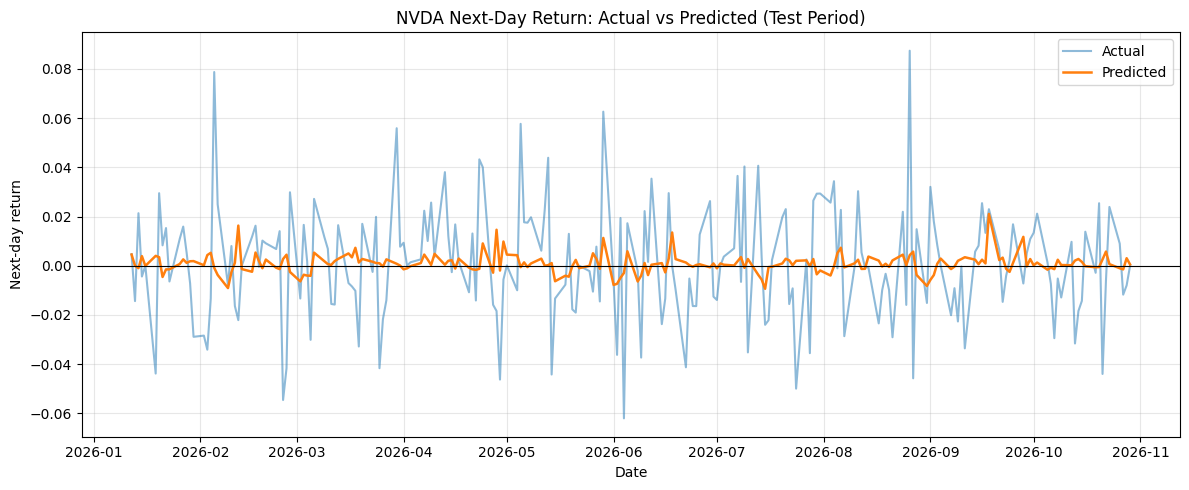

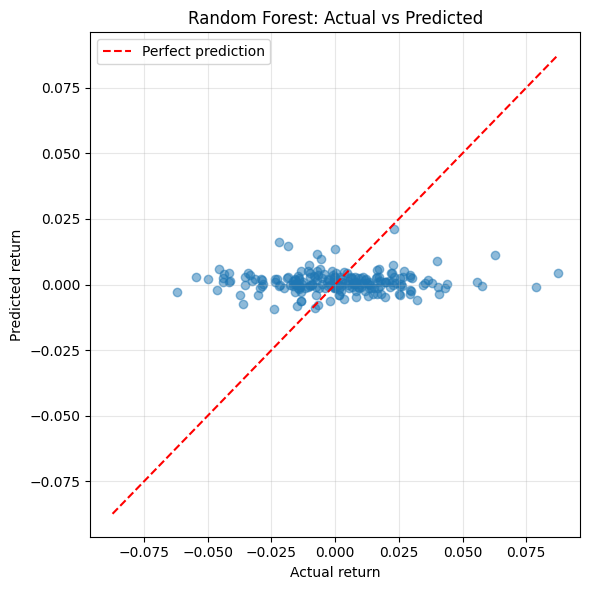

In [11]:
# Feature importance
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(7, 6), title="Random Forest Feature Importance")
plt.tight_layout(); plt.savefig("rf_importance.png", dpi=150); plt.show()

# Actual vs predicted over time
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label="Actual", alpha=0.5)
plt.plot(pred_s.index, pred_s, label="Predicted", linewidth=1.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("NVDA Next-Day Return: Actual vs Predicted (Test Period)")
plt.xlabel("Date"); plt.ylabel("Next-day return"); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("rf_actual_vs_predicted.png", dpi=150); plt.show()

# Scatter of actual vs predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.5)
lim = max(abs(y_test).max(), abs(pred).max())
plt.plot([-lim, lim], [-lim, lim], "r--", label="Perfect prediction")
plt.xlabel("Actual return"); plt.ylabel("Predicted return"); plt.legend(); plt.grid(True, alpha=0.3)
plt.title("Random Forest: Actual vs Predicted")
plt.tight_layout(); plt.savefig("rf_scatter.png", dpi=150); plt.show()

Direction calls on the price chart, One tree from the forest and Sentiment vs next-day price change

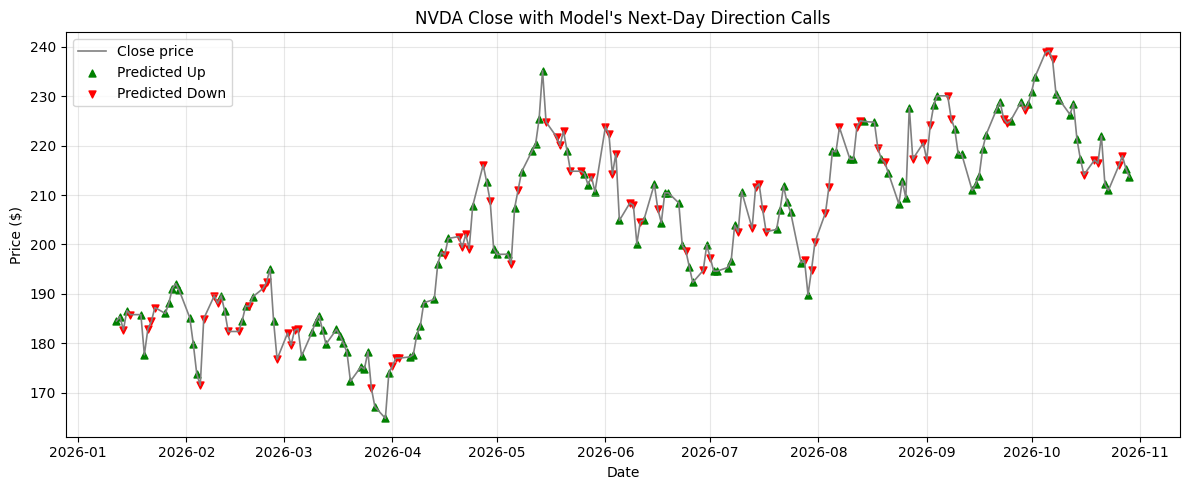

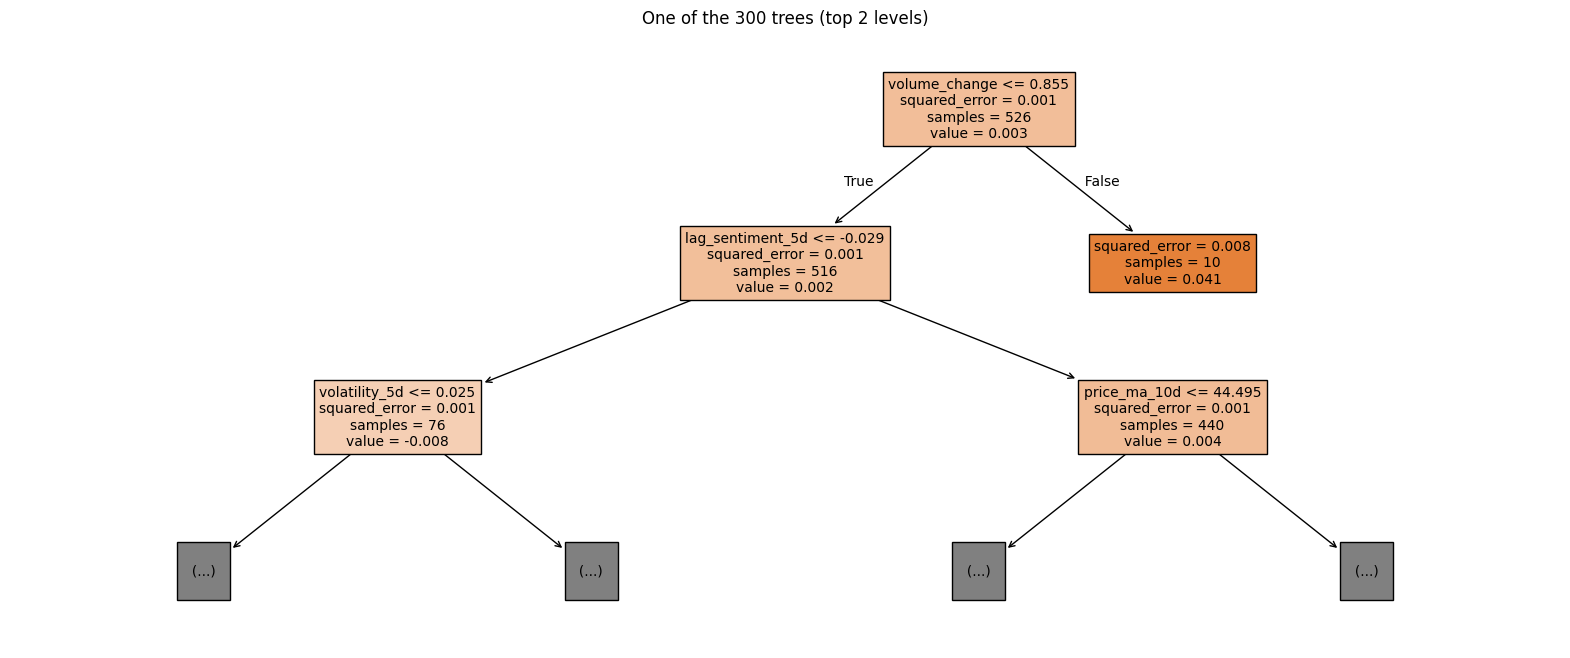

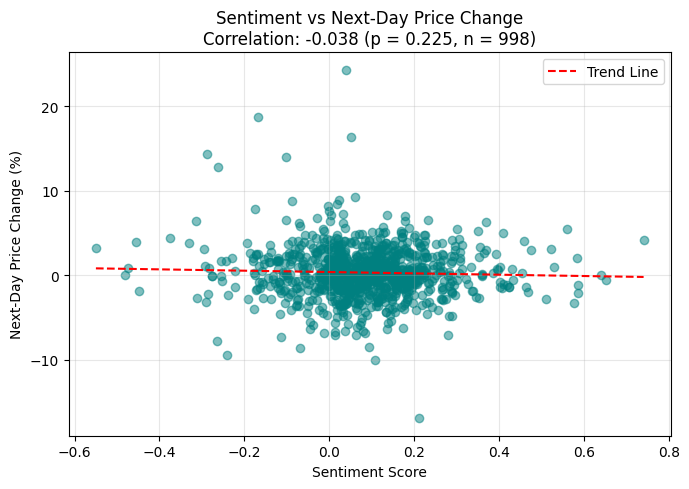

In [12]:
# Direction calls on the price chart
close = test["stock"]; up = pred_s > 0
plt.figure(figsize=(12, 5))
plt.plot(close.index, close, color="gray", linewidth=1.2, label="Close price")
plt.scatter(close.index[up],  close[up],  marker="^", color="green", s=25, label="Predicted Up")
plt.scatter(close.index[~up], close[~up], marker="v", color="red",   s=25, label="Predicted Down")
plt.title("NVDA Close with Model's Next-Day Direction Calls"); plt.legend(); plt.grid(True, alpha=0.3)
plt.xlabel("Date"); plt.ylabel("Price ($)")
plt.tight_layout(); plt.savefig("rf_direction_on_price.png", dpi=150); plt.show()

# One tree from the forest
plt.figure(figsize=(20, 8))
plot_tree(rf.estimators_[0], feature_names=features, max_depth=2, filled=True, fontsize=10)
plt.title("One of the 300 trees (top 2 levels)")
plt.savefig("rf_single_tree.png", dpi=150); plt.show()

# Sentiment vs next-day price change
cov = data[data["news_covered"] == 1]
x, y = cov["sentiment"], cov["target_return"] * 100
r, p = pearsonr(x, y)
slope, icpt = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.5, color="teal")
plt.plot(xs, slope * xs + icpt, "r--", label="Trend Line")
plt.title(f"Sentiment vs Next-Day Price Change\nCorrelation: {r:.3f} (p = {p:.3f}, n = {len(cov)})")
plt.xlabel("Sentiment Score"); plt.ylabel("Next-Day Price Change (%)"); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("sentiment_vs_next_day.png", dpi=150); plt.show()